# 1 – Numerical Integration: How Much Energy Is Generated per Day?

**Dataset:** Kaggle – *Solar Power Generation Data* (Ani Kannal), Plant 1. Measurements from 22 inverters, recorded every 15 minutes from May 15 to June 17, 2020.

The inverters report instantaneous power (`AC_POWER`, kW) every 15 minutes. Daily energy is the integral of power over time:
$$E = \int P(t)\,dt \quad [\text{kW} \times \text{hours} = \text{kWh}]$$
We estimate the integral using the trapezoidal rule, Simpson's rule, and Romberg integration, and compare the results with the inverter's own energy counter (`TOTAL_YIELD`).

**Development note:** AI assistance was used for parts of the code and for translation of the notebook.

Import the required libraries. The CSV files may be placed alongside the notebook or in the `../data` directory.

**Reproducibility note:** Some cached plots were generated before the English translation and retain their original Turkish labels. Running all cells regenerates the figures with English labels. The numerical results reported here are from the original notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate

VERI = Path(".") if Path("Plant_1_Generation_Data.csv").exists() else Path("../data")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Data

Power is zero at night, and generation occurs between 06:00 and 18:30. We therefore integrate over **04:00–20:00**: 16 hours = 64 intervals = 65 points.
Since 64 = 2⁶, this grid is also suitable for Romberg integration. Only inverter-days containing all 65 measurement points are included.
Reference energy: $E_{\text{ref}} = \text{TOTAL\_YIELD}(20{:}00) - \text{TOTAL\_YIELD}(04{:}00)$.

In [2]:
df = pd.read_csv(VERI / "Plant_1_Generation_Data.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%d-%m-%Y %H:%M")
df["tarih"] = df["DATE_TIME"].dt.date
df["saat"] = df["DATE_TIME"].dt.hour + df["DATE_TIME"].dt.minute / 60
df = df.sort_values(["SOURCE_KEY", "DATE_TIME"])

pencere = df[(df["saat"] >= 4) & (df["saat"] <= 20)]
gunler, ref = {}, {}          # (inverter, date) -> power array and reference energy
for anahtar, g in pencere.groupby(["SOURCE_KEY", "tarih"]):
    if len(g) == 65:
        gunler[anahtar] = g["AC_POWER"].to_numpy()
        ref[anahtar] = g["TOTAL_YIELD"].iloc[-1] - g["TOTAL_YIELD"].iloc[0]

h = 0.25                      # step size: 15 minutes = 0.25 hours
t = np.linspace(4, 20, 65)
print("Number of inverters       :", df["SOURCE_KEY"].nunique())
print("Complete (65-point) inverter-days:", len(gunler), "/", pencere.groupby(["SOURCE_KEY", "tarih"]).ngroups)

Number of inverters       : 22
Complete (65-point) inverter-days: 487 / 748


Consider a single day for one inverter. The afternoon power curve fluctuates, possibly because of cloud cover. These fluctuations are relevant to the comparison of integration methods.

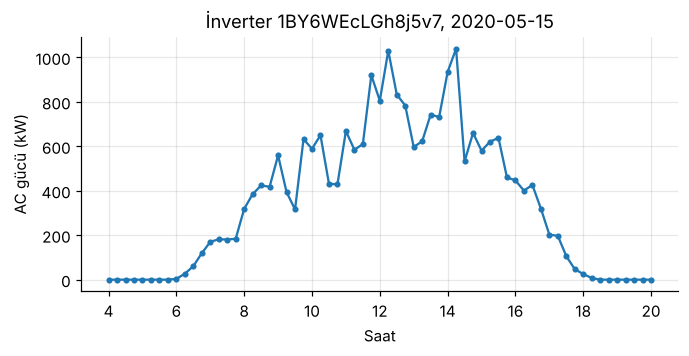

In [3]:
ornek = list(gunler)[0]
plt.figure(figsize=(7, 3))
plt.plot(t, gunler[ornek], "o-", ms=3)
plt.xlabel("Time (hours)"); plt.ylabel("AC power (kW)")
plt.title(f"Inverter {ornek[0]}, {ornek[1]}")
plt.xticks(range(4, 21, 2))
plt.show()

## 2. Numerical Methods

Let $n$ be the number of equal intervals, $h$ the step size, and $f_i$ the sampled values:
* **Trapezoidal rule:** $T(h) = h\left[\tfrac12 f_0 + f_1 + \dots + f_{n-1} + \tfrac12 f_n\right]$, error $O(h^2)$.
* **Simpson's rule** ($n$ even): $S(h) = \tfrac{h}{3}\left[f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 4f_{n-1} + f_n\right]$, error $O(h^4)$.
* **Romberg integration:** $R_{k,0}$ is the trapezoidal approximation with step size $h_k = (b-a)/2^k$. Richardson extrapolation gives $R_{k,j} = R_{k,j-1} + \dfrac{R_{k,j-1} - R_{k-1,j-1}}{4^j - 1}$.

These error orders assume sufficient smoothness of the integrand.

In [4]:
def trapez(f, h):
    """Composite trapezoidal rule. f: equally spaced samples; h: step size."""
    f = np.asarray(f, dtype=float)
    return h * (f.sum() - 0.5 * (f[0] + f[-1]))


def simpson(f, h):
    """Composite Simpson rule. The number of intervals (len(f) - 1) must be even."""
    f = np.asarray(f, dtype=float)
    if (len(f) - 1) % 2:
        raise ValueError("Simpson rule requires an even number of intervals")
    return h / 3 * (f[0] + f[-1] + 4 * f[1:-1:2].sum() + 2 * f[2:-1:2].sum())


def romberg(f, h):
    """Romberg integration from samples. The number of intervals must be a power of two. Returns the best estimate."""
    f = np.asarray(f, dtype=float)
    k = int(np.log2(len(f) - 1))
    R = np.zeros((k + 1, k + 1))
    for i in range(k + 1):                 # i = 0: one interval (coarsest grid)
        adim = 2 ** (k - i)
        R[i, 0] = trapez(f[::adim], h * adim)
    for i in range(1, k + 1):
        for j in range(1, i + 1):
            R[i, j] = R[i, j - 1] + (R[i, j - 1] - R[i - 1, j - 1]) / (4**j - 1)
    return R[k, k]

Compare the implementations with SciPy's built-in functions using the power measurements from the example day.

In [5]:
p = gunler[ornek]
print(f"trapez : custom {trapez(p, h):.6f}   SciPy {integrate.trapezoid(p, dx=h):.6f}")
print(f"simpson: custom {simpson(p, h):.6f}   SciPy {integrate.simpson(p, dx=h):.6f}")
print(f"romberg: custom {romberg(p, h):.6f}   SciPy {integrate.romb(p, dx=h):.6f}")

trapez : custom 5761.637649   SciPy 5761.637649
simpson: custom 5815.328373   SciPy 5815.328373
romberg: custom 5843.811523   SciPy 5843.811523


## 3. Benchmark Test: $\int_0^1 e^x\,dx = e - 1$

We halve the step size and measure the absolute error. The slope on a log-log plot indicates the order of convergence: we expect approximately 2 for the trapezoidal rule and 4 for Simpson's rule.

Trapezoidal slope : 2.0
Simpson slope: 3.99


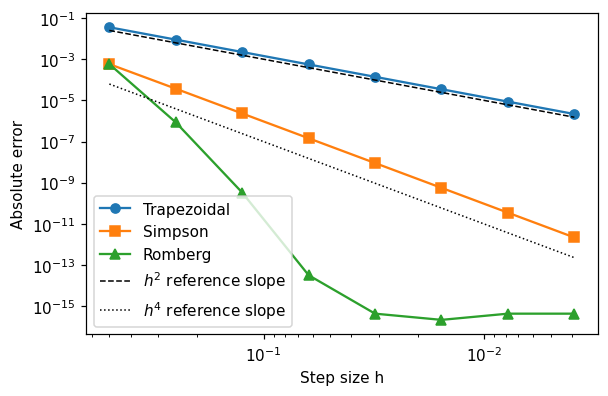

In [6]:
tam = np.e - 1
n_list = 2 ** np.arange(1, 9)
hs = 1 / n_list
hata_T = [abs(trapez(np.exp(np.linspace(0, 1, n + 1)), 1 / n) - tam) for n in n_list]
hata_S = [abs(simpson(np.exp(np.linspace(0, 1, n + 1)), 1 / n) - tam) for n in n_list]
hata_R = [abs(romberg(np.exp(np.linspace(0, 1, n + 1)), 1 / n) - tam) for n in n_list]

plt.figure(figsize=(6, 3.8))
plt.loglog(hs, hata_T, "o-", label="Trapezoidal")
plt.loglog(hs, hata_S, "s-", label="Simpson")
plt.loglog(hs, np.maximum(hata_R, 1e-17), "^-", label="Romberg")
plt.loglog(hs, 0.1 * hs**2, "k--", lw=1, label="$h^2$ reference slope")
plt.loglog(hs, 0.001 * hs**4, "k:", lw=1, label="$h^4$ reference slope")
plt.gca().invert_xaxis()
plt.xlabel("Step size h"); plt.ylabel("Absolute error")
plt.legend(); plt.show()

print("Trapezoidal slope :", round(np.polyfit(np.log(hs), np.log(hata_T), 1)[0], 2))
print("Simpson slope:", round(np.polyfit(np.log(hs[:5]), np.log(hata_S[:5]), 1)[0], 2))

The results agree with theory: the trapezoidal slope is approximately 2, Simpson's slope is approximately 4, and Romberg integration reaches machine precision (approximately $10^{-16}$) after a few refinements.
The Simpson slope is fitted using the first five points, as rounding errors can affect the smallest errors.

## 4. Real Data: Daily Energy

For each inverter-day, we integrate the measured power using all three methods and compute the relative error against the reference energy:
$\text{error} = |E_{\text{method}} - E_{\text{ref}}|\, /\, E_{\text{ref}}$.

In [7]:
sonuc = pd.DataFrame([
    {"Trapezoidal":  abs(trapez(p, h) - ref[k]) / ref[k],
     "Simpson": abs(simpson(p, h) - ref[k]) / ref[k],
     "Romberg": abs(romberg(p, h) - ref[k]) / ref[k]}
    for k, p in gunler.items()
])
print(f"Mean daily energy (per inverter): {np.mean(list(ref.values())):.0f} kWh\n")
tablo = (sonuc.median() * 100).round(2).to_frame("Median relative error (%)")
tablo

Mean daily energy (per inverter): 6982 kWh



,Median relative error (%)
Trapezoidal,0.28
Simpson,0.43
Romberg,0.50


**The trapezoidal rule has the lowest median relative error**, followed by Simpson's rule and Romberg integration. This is the reverse of the ranking in the benchmark test.

## 5. Downsampling: What Happens as the Measurement Interval Increases?

We retain every second, fourth, and eighth point to obtain sampling intervals of 30, 60, and 120 minutes, then compute the errors again.

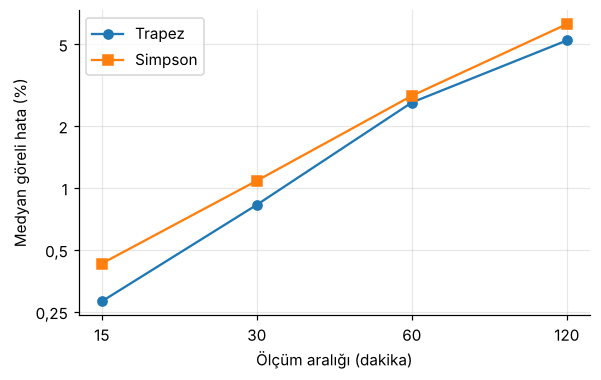

,Trapezoidal (%),Simpson (%)
interval (min),,
15,0.28,0.43
30,0.83,1.08
60,2.60,2.80
120,5.21,6.25


In [8]:
seyreltme = [1, 2, 4, 8]                  # 15, 30, 60, 120 minutes
h_dk = [15 * s for s in seyreltme]
med_T, med_S = [], []
for s in seyreltme:
    med_T.append(np.median([abs(trapez(p[::s], h * s) - ref[k]) / ref[k] for k, p in gunler.items()]) * 100)
    med_S.append(np.median([abs(simpson(p[::s], h * s) - ref[k]) / ref[k] for k, p in gunler.items()]) * 100)

plt.figure(figsize=(6, 3.6))
plt.loglog(h_dk, med_T, "o-", label="Trapezoidal")
plt.loglog(h_dk, med_S, "s-", label="Simpson")
plt.xticks(h_dk, h_dk); plt.minorticks_off()
plt.yticks([0.25, 0.5, 1, 2, 5], ["0.25", "0.5", "1", "2", "5"])
plt.xlabel("Sampling interval (minutes)"); plt.ylabel("Median relative error (%)")
plt.legend(); plt.show()

pd.DataFrame({"Trapezoidal (%)": med_T, "Simpson (%)": med_S}, index=pd.Index(h_dk, name="interval (min)")).round(2)

## Conclusion

* At 15-minute sampling intervals, the trapezoidal rule estimates daily energy with a **median relative error of 0.28%**, compared with 0.43% for Simpson's rule and 0.50% for Romberg integration.
* For the smooth benchmark function ($e^x$), the observed accuracy ranking agrees with theory: Romberg, Simpson, then trapezoidal. The different ranking for the solar data highlights the importance of the integrand and sampling conditions.
* **Why?** The higher-order accuracy of Simpson's rule and Romberg integration relies on sufficient smoothness. Rapid fluctuations in power, potentially caused by clouds, can reduce this advantage. The power curve also has zero-valued endpoints.
* The median trapezoidal error increases as sampling becomes less frequent: approximately 0.8% at 30 minutes, 2.6% at 60 minutes, and 5.2% at 120 minutes. Simpson's rule does not outperform the trapezoidal rule at these intervals.
* Sampling limitations may contribute to the remaining error: changes in power between measurements cannot be directly observed by any of these integration methods.